# Databases - Station networks

This tutorial covers `SemiSpatialDB`, a database whose records carry a `feature_id`: the key of a place, such as a station, kept outside the database. The example expands the single station of the basics tutorial into a network of 30 weather stations. The geometries of the stations live in their own file, and `geopandas` joins them back to the records when a map is needed.

```{seealso}
Check out the {doc}`Databases - Basics <databases_01>` tutorial first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Polygon

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.databases import SemiSpatialDB
from plans.datasets.analyst import GeoUnivar

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/databases")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\databases


## The station network

Lets place 30 stations at random over a region, in geographic coordinates. Each station has an integer `id`, which will be its `feature_id` in the database, and a name:

In [2]:
rng = np.random.default_rng(seed=7)  # ensure reproducibility

n_stations = 30
stations = gpd.GeoDataFrame(
    data={
        "id": np.arange(101, 101 + n_stations),
        "name": [f"ST{i}" for i in range(101, 101 + n_stations)],
    },
    geometry=gpd.points_from_xy(
        x=rng.uniform(low=-53.5, high=-50.0, size=n_stations),
        y=rng.uniform(low=-31.5, high=-28.0, size=n_stations),
    ),
    crs="EPSG:4674",
)
stations.head()

,id,name,geometry
0,101,ST101,POINT (-51.31217 -29.76094)
1,102,ST102,POINT (-50.35975 -30.6337)
2,103,ST103,POINT (-50.7851 -31.45872)
3,104,ST104,POINT (-52.71177 -30.82659)
4,105,ST105,POINT (-52.44942 -29.07789)


The stations are saved to their own GeoPackage. The database never holds them; it only stores their ids:

In [3]:
file_stations = OUTPUT_DIR / "stations.gpkg"
stations.to_file(filename=file_stations, layer="stations", driver="GPKG")

## Creating the database

The setup is the same as for `DataBase`. The specs describe the datasets of the whole network, not of one station:

In [4]:
def make_spec(name, abstract, variable, statistic):
    # one spec of monthly station data
    return {
        "name": name,
        "abstract": abstract,
        "method": f"{statistic} of daily readings",
        "timestep": "1M",
        "extent": "station",
        "scale": 1,
        "offset": 0,
        "start": "2001-01-01",
        "end": None,
        "variable_name": variable,
        "statistic_name": statistic,
        "source_name": "INMET",
    }


specs = [
    make_spec("TAS_MONTHLY", "Monthly mean air temperature (synthetic)", "surface air temperature", "mean"),
    make_spec("PPT_MONTHLY", "Monthly rainfall total (synthetic)", "precipitation", "sum"),
]
file_specs = OUTPUT_DIR / "network_specs.json"
file_specs.write_text(json.dumps(specs, indent=2), encoding="utf-8")

db = SemiSpatialDB(name="Network")
file_db = db.new(
    config={
        "database": {"path": str(OUTPUT_DIR / "network.db")},
        "specs": {"path": str(file_specs)},
    },
    overwrite=True,
)
print(db.inspect_schema(table="records", quiet=True))

[Network]
  records  (0 rows)
    id                   INTEGER
    inserted             INTEGER
    datetime             INTEGER
    value                REAL
    flag_value           INTEGER
    spec_id              INTEGER
    feature_id           INTEGER



## Sample data

Temperature gets colder to the south, and rainfall grows to the east, so maps will have a pattern to show. Both follow a seasonal cycle. About 3% of the months are missing at random, as in a real network:

In [5]:
dates = pd.date_range(start="2001-01-01", end="2020-12-01", freq="MS")
season = np.cos(2 * np.pi * (dates.month - 1) / 12)

frames_tas, frames_ppt = [], []
for station in stations.itertuples():
    south = (-28.0 - station.geometry.y) / 3.5  # 0 north, 1 south
    east = (station.geometry.x + 53.5) / 3.5  # 0 west, 1 east
    tas = 21 - 4 * south + 5 * season + rng.normal(scale=1, size=len(dates))
    mean_ppt = (100 + 60 * east) * (1 - 0.25 * season)
    ppt = rng.gamma(shape=4, scale=mean_ppt / 4)
    ppt[rng.random(size=len(dates)) < 0.03] = np.nan
    frames_tas.append(pd.DataFrame({"datetime": dates, "value": tas, "feature_id": station.id}))
    frames_ppt.append(pd.DataFrame({"datetime": dates, "value": ppt, "feature_id": station.id}))

df_tas = pd.concat(frames_tas, ignore_index=True)
df_ppt = pd.concat(frames_ppt, ignore_index=True)
df_ppt.head()

,datetime,value,feature_id
0,2001-01-01,97.241547,101
1,2001-02-01,130.277754,101
2,2001-03-01,80.172123,101
3,2001-04-01,263.717471,101
4,2001-05-01,146.864231,101


## Inserting records

Records now need a `feature_id` column. One call inserts the whole network for a spec. Missing values are dropped, which is the default:

In [6]:
db.insert_records(dataframe=df_tas, spec_name="TAS_MONTHLY", flag=1)
db.insert_records(dataframe=df_ppt, spec_name="PPT_MONTHLY", flag=1)
print(db.inspect_records(head=5, quiet=True))

[Network]
  records  (14176 rows)
    id                   INTEGER
    inserted             INTEGER
    datetime             INTEGER
    value                REAL
    flag_value           INTEGER
    spec_id              INTEGER
    feature_id           INTEGER

  head (5)
 id         inserted         datetime     value  flag_value  spec_id  feature_id
  1 2026-11-06 20:59 2001-01-01 00:00 23.311831           1        1         101
  2 2026-11-06 20:59 2001-02-01 00:00 23.520759           1        1         101
  3 2026-11-06 20:59 2001-03-01 00:00 21.024186           1        1         101
  4 2026-11-06 20:59 2001-04-01 00:00 19.114762           1        1         101
  5 2026-11-06 20:59 2001-05-01 00:00 15.300299           1        1         101



## Querying the network

The `feature_id` key takes one id or a list of any length. Rows come ordered by spec, station and date:

In [7]:
df = db.query_records(query_dict={"spec_name": "PPT_MONTHLY", "feature_id": [101, 102]})
df[["datetime", "value", "feature_id"]].head()

,datetime,value,feature_id
0,2001-01-01 00:00:00+00:00,97.241547,101
1,2001-02-01 00:00:00+00:00,130.277754,101
2,2001-03-01 00:00:00+00:00,80.172123,101
3,2001-04-01 00:00:00+00:00,263.717471,101
4,2001-05-01 00:00:00+00:00,146.864231,101


In wide format, columns are a `MultiIndex` of spec and station:

In [8]:
wide = db.query_records(query_dict={"spec_name": "TAS_MONTHLY", "wide": True})
wide.iloc[:5, :4]

spec_name                 TAS_MONTHLY                                 
feature_id                        101        102        103        104
datetime                                                              
2001-01-01 00:00:00+00:00   23.311831  21.181583  20.836786  21.617143
2001-02-01 00:00:00+00:00   23.520759  22.094754  22.293410  22.677714
2001-03-01 00:00:00+00:00   21.024186  18.271938  18.863987  21.207404
2001-04-01 00:00:00+00:00   19.114762  18.361879  16.975705  19.888797
2001-05-01 00:00:00+00:00   15.300299  14.764002  15.176272  16.560136

## Joining records to the stations

Maps need one value per station. Lets compute the mean annual rainfall, using only years with all 12 months, so a missing month does not lower the total:

In [9]:
df = db.query_records(query_dict={"spec_name": "PPT_MONTHLY"})
df["year"] = df["datetime"].dt.year
yearly = df.groupby(["feature_id", "year"])["value"].agg(["sum", "count"])
annual = (
    yearly[yearly["count"] == 12]
    .groupby("feature_id")["sum"]
    .mean()
    .rename("ppt_annual")
    .reset_index()
)
annual.head()

,feature_id,ppt_annual
0,101,1587.479636
1,102,1858.045009
2,103,1845.836445
3,104,1328.138769
4,105,1399.430228


The stations come from their file, and `.merge()` joins the values by matching `id` with `feature_id`:

In [10]:
stations = gpd.read_file(filename=file_stations, layer="stations")
gdf = stations.merge(annual, left_on="id", right_on="feature_id")
gdf.head()

,id,name,geometry,feature_id,ppt_annual
0,101,ST101,POINT (-51.31217 -29.76094),101,1587.479636
1,102,ST102,POINT (-50.35975 -30.6337),102,1858.045009
2,103,ST103,POINT (-50.7851 -31.45872),103,1845.836445
3,104,ST104,POINT (-52.71177 -30.82659),104,1328.138769
4,105,ST105,POINT (-52.44942 -29.07789),105,1399.430228


## Mapping with `GeoUnivar`

A `GeoUnivar` takes the joined `GeoDataFrame` and the column of values, and shows the map next to the data, the histogram and the CDF:

```{seealso}
Check out the {doc}`Univariate data - Geospatial <univar_03_geo>` tutorial for the options of the map.
```

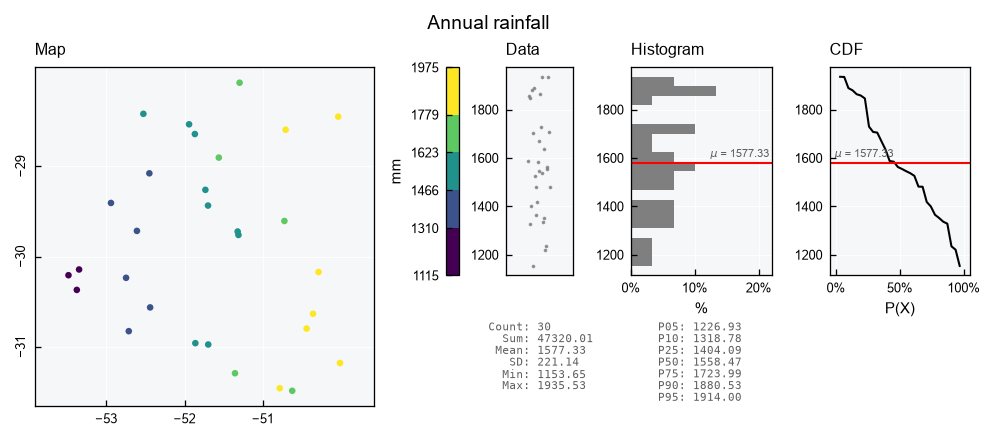

In [11]:
gv = GeoUnivar(name="Annual rainfall", alias="PPT")
gv.varname = "Mean annual rainfall"
gv.units = "mm"
gv.set_data(input_df=gdf, input_varfield="ppt_annual")
gv.view()

## Selecting stations by area

Spatial questions are answered outside the database too. Lets draw a catchment, find the stations inside it with `geopandas`, and pass their ids to the query:

In [12]:
angle = np.linspace(start=0, stop=2 * np.pi, num=60, endpoint=False)
radius = 0.9 + 0.2 * np.sin(3 * angle)
catchment = gpd.GeoDataFrame(
    data={"name": ["Catchment"]},
    geometry=[Polygon(shell=list(zip(-51.6 + radius * np.cos(angle), -29.6 + radius * np.sin(angle))))],
    crs="EPSG:4674",
)
inside = stations[stations.within(other=catchment.geometry.iloc[0])]
ids = inside["id"].tolist()
print(f"{len(ids)} stations inside: {ids}")

7 stations inside: [101, 105, 115, 116, 118, 119, 130]


The map shows the catchment with the `helper_geometry` key:

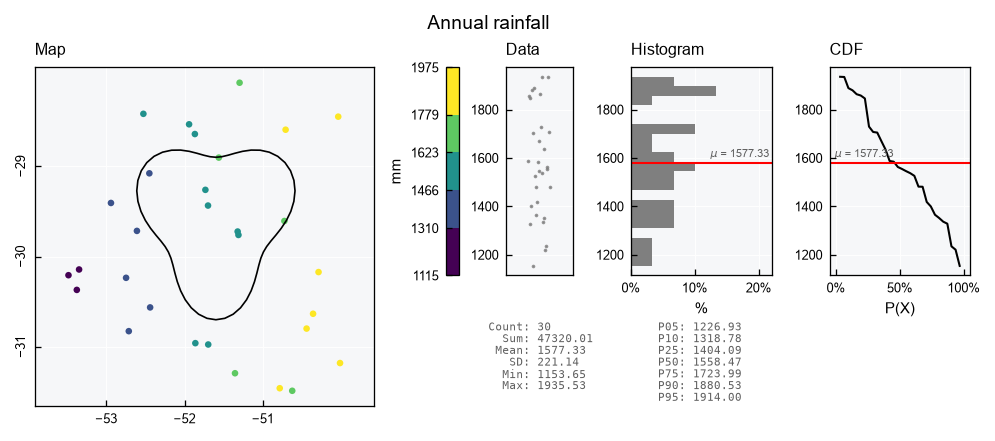

In [13]:
gv.view_specs["helper_geometry"] = catchment
gv.view()

The query returns the records of those stations only. Their average gives a simple areal rainfall for the catchment:

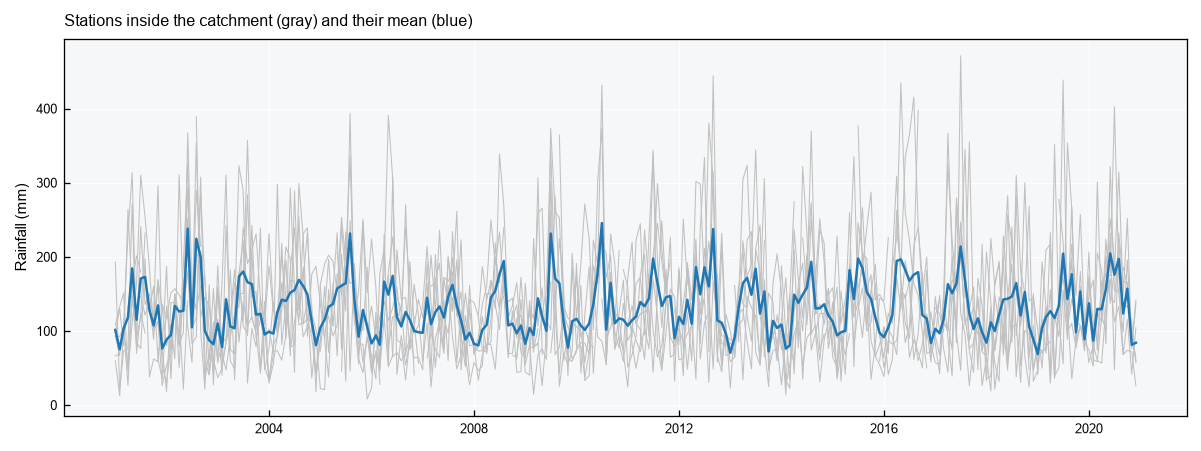

In [14]:
wide = db.query_records(query_dict={"spec_name": "PPT_MONTHLY", "feature_id": ids, "wide": True})
areal = wide.mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(wide.index, wide.values, color="silver", lw=0.5)
ax.plot(areal.index, areal.values, color="tab:blue", lw=1.2)
ax.set_ylabel("Rainfall (mm)")
ax.set_title("Stations inside the catchment (gray) and their mean (blue)", loc="left")
plt.tight_layout()
plt.show()

In [15]:
db.close()